In [2]:
import torch, os
print('PyTorch :', torch.__version__)
print('CUDA    :', torch.cuda.is_available())
print('GPUs    :', torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f'  GPU {i} :', torch.cuda.get_device_name(i))

PyTorch : 2.10.0+cu128
CUDA    : True
GPUs    : 2
  GPU 0 : Tesla T4
  GPU 1 : Tesla T4


In [3]:
import torch, os

DATA_ROOT = '/kaggle/input/datasets/rayeneeeeeeeeee/nctcrche100k/9 Class Colon Cancer Histopathological Image'
OUT_DIR   = '/kaggle/working'
CKPT_PATH = os.path.join(OUT_DIR, 'protonet_best.pt')


N_WAY   = 5   
K_SHOT  = 5    
Q_QUERY = 10   
META_BS = 4   


LR         = 0.001
NUM_EPOCHS = 20


TRAIN_EPS = 400
VAL_EPS   = 100
TEST_EPS  = 100


IMG_SIZE = 128

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('Device   :', DEVICE)
print('GPUs     :', torch.cuda.device_count())
print('Data root:', os.path.isdir(DATA_ROOT))
print(f'FSL      : {N_WAY}-way {K_SHOT}-shot, {Q_QUERY} queries')
print(f'LR       : {LR}')
print('No inner loop — classification by distance to prototypes')

Device   : cuda
GPUs     : 2
Data root: True
FSL      : 5-way 5-shot, 10 queries
LR       : 0.001
No inner loop — classification by distance to prototypes


In [4]:
import os, random

assert os.path.isdir(DATA_ROOT), f'Not found: {DATA_ROOT}'

classes = sorted([
    d for d in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, d))
])
print(f'Found {len(classes)} classes:')

class_to_files = {}
for c in classes:
    folder = os.path.join(DATA_ROOT, c)
    files  = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(('.jpg','.jpeg','.png','.tif','.tiff'))
    ]
    class_to_files[c] = files
    print(f'  {c:45s}: {len(files):6,}')

print(f'\nTotal: {sum(len(v) for v in class_to_files.values()):,}')
assert len(classes) >= N_WAY

Found 9 classes:
  1. Normal                                    :  8,763
  2. Tumor                                     : 14,317
  3. Stroma                                    : 10,446
  4. Lympho                                    : 11,557
  5. Complex                                   : 13,536
  6. Debris                                    : 11,512
  7. Mucosa                                    :  8,896
  8. Adipose                                   : 10,407
  9. Background                                : 10,566

Total: 100,000


In [5]:
random.seed(42)

all_cls = list(class_to_files.keys())
random.shuffle(all_cls)

n_tr = max(int(0.6 * len(all_cls)), N_WAY)
n_vl = max(int(0.2 * len(all_cls)), N_WAY)

if n_tr + n_vl + N_WAY <= len(all_cls):
    train_cls = all_cls[:n_tr]
    val_cls   = all_cls[n_tr : n_tr + n_vl]
    test_cls  = all_cls[n_tr + n_vl :]
    print('Class-disjoint split')
    train_dict = {c: class_to_files[c] for c in train_cls}
    val_dict   = {c: class_to_files[c] for c in val_cls}
    test_dict  = {c: class_to_files[c] for c in test_cls}
else:
    print('Image-level split')
    def make_img_dict(fs, fe):
        d = {}
        for c, files in class_to_files.items():
            f = files[:]; random.shuffle(f)
            d[c] = f[int(fs*len(f)) : int(fe*len(f))]
        return d
    train_dict = make_img_dict(0.00, 0.70)
    val_dict   = make_img_dict(0.70, 0.85)
    test_dict  = make_img_dict(0.85, 1.00)

for name, d in [('Train', train_dict), ('Val', val_dict), ('Test', test_dict)]:
    total = sum(len(v) for v in d.values())
    print(f'{name:5s}: {len(d)} classes, {total:,} images')

Image-level split
Train: 9 classes, 69,996 images
Val  : 9 classes, 15,000 images
Test : 9 classes, 15,004 images


In [ ]:
import random
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T


class FSLDataset(Dataset):
    def __init__(self, class_dict, n_way, k_shot, q_query,
                 n_episodes, img_size=128, augment=False):
        super().__init__()
        self.class_dict = class_dict
        self.classes    = list(class_dict.keys())
        self.n_way      = n_way
        self.k_shot     = k_shot
        self.q_query    = q_query
        self.n_episodes = n_episodes

        need  = k_shot + q_query
        short = [c for c, f in class_dict.items() if len(f) < need]
        assert not short, f'Too few images: {short}'

        aug = [
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.ColorJitter(0.2, 0.2, 0.2, 0.05),
        ] if augment else []

        self.transform = T.Compose(aug + [
            T.Resize([img_size, img_size]),
            T.ToTensor(),
            T.Normalize([0.485, 0.456, 0.406],
                        [0.229, 0.224, 0.225]),
        ])

    def __len__(self): return self.n_episodes

    def _load(self, path):
        return self.transform(Image.open(path).convert('RGB'))

    def __getitem__(self, _):
        chosen = random.sample(self.classes, self.n_way)
        sup_imgs, qry_imgs = [], []
        sup_tgts, qry_tgts = [], []
        for label, cls in enumerate(chosen):
            paths = random.sample(
                self.class_dict[cls],
                self.k_shot + self.q_query)
            for p in paths[:self.k_shot]:
                sup_imgs.append(self._load(p))
                sup_tgts.append(label)
            for p in paths[self.k_shot:]:
                qry_imgs.append(self._load(p))
                qry_tgts.append(label)
        return (torch.stack(sup_imgs),
                torch.stack(qry_imgs),
                torch.LongTensor(sup_tgts),
                torch.LongTensor(qry_tgts))


def collate_episodes(batch): return batch

train_ds = FSLDataset(train_dict, N_WAY, K_SHOT, Q_QUERY,
                      TRAIN_EPS, IMG_SIZE, augment=True)
val_ds   = FSLDataset(val_dict,   N_WAY, K_SHOT, Q_QUERY,
                      VAL_EPS,   IMG_SIZE)
test_ds  = FSLDataset(test_dict,  N_WAY, K_SHOT, Q_QUERY,
                      TEST_EPS,  IMG_SIZE)

train_dl = DataLoader(train_ds, META_BS, shuffle=True,
                      num_workers=2, collate_fn=collate_episodes)
val_dl   = DataLoader(val_ds,   META_BS, shuffle=False,
                      num_workers=2, collate_fn=collate_episodes)
test_dl  = DataLoader(test_ds,  META_BS, shuffle=False,
                      num_workers=2, collate_fn=collate_episodes)

print(f'Train : {len(train_dl)} batches  ({TRAIN_EPS} episodes)')
print(f'Val   : {len(val_dl)} batches  ({VAL_EPS} episodes)')
print(f'Test  : {len(test_dl)} batches  ({TEST_EPS} episodes)')

In [ ]:
import torch.nn as nn
import torchvision.models as models


class ProtoNet(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT)

        self.frozen = nn.Sequential(
            backbone.conv1, backbone.bn1,
            backbone.relu, backbone.maxpool,
            backbone.layer1, backbone.layer2,
            backbone.layer3,
        )
        for p in self.frozen.parameters():
            p.requires_grad = False

        self.encoder = nn.Sequential(
            backbone.layer4,
            backbone.avgpool,
            nn.Flatten(),
        )

    def forward(self, x):
        with torch.no_grad():
            x = self.frozen(x)
        x = self.encoder(x)                         # (B, 512)
        return nn.functional.normalize(x, dim=1)    # unit-norm embedding


model = ProtoNet().to(DEVICE)

frozen_p    = sum(p.numel() for p in model.frozen.parameters())
trainable_p = sum(p.numel() for p in model.parameters()
                  if p.requires_grad)
print(f'Frozen params    : {frozen_p:,}')
print(f'Trainable params : {trainable_p:,}')

dummy  = torch.zeros(4, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
embed  = model(dummy)
print(f'Embedding shape  : {tuple(embed.shape)}')

In [ ]:
def euclidean_dist(a, b):
    """Squared Euclidean distance between every row of a and every row of b."""
    n = a.size(0); m = b.size(0)
    a = a.unsqueeze(1).expand(n, m, -1)
    b = b.unsqueeze(0).expand(n, m, -1)
    return torch.pow(a - b, 2).sum(2)


def proto_episode(encoder, support, query, s_tgt, q_tgt,
                  n_way, k_shot):
    # support is ordered class by class (k_shot images per class)
    sup_emb    = encoder(support)
    prototypes = sup_emb.view(n_way, k_shot, -1).mean(1)
    qry_emb    = encoder(query)
    dists      = euclidean_dist(qry_emb, prototypes)
    logits     = -dists
    loss       = nn.functional.cross_entropy(logits, q_tgt)
    acc        = (logits.argmax(1) == q_tgt
                  ).float().mean().item() * 100
    return loss, acc


optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad,
           model.parameters()), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=10, gamma=0.5)

print('ProtoNet helpers defined')

In [ ]:
import time, gc


def run_epoch(model, loader, phase='train'):
    is_train = (phase == 'train')
    model.train() if is_train else model.eval()
    accs, losses = [], []

    for batch in loader:
        if is_train:
            optimizer.zero_grad(set_to_none=True)
        batch_loss = torch.tensor(0.0, device=DEVICE)

        for (support, query, s_tgt, q_tgt) in batch:
            support = support.to(DEVICE)
            query   = query.to(DEVICE)
            s_tgt   = s_tgt.to(DEVICE)
            q_tgt   = q_tgt.to(DEVICE)

            with torch.set_grad_enabled(is_train):
                loss, acc = proto_episode(
                    model, support, query, s_tgt, q_tgt,
                    N_WAY, K_SHOT)
            batch_loss = batch_loss + loss
            accs.append(acc)

        batch_loss = batch_loss / len(batch)
        if is_train:
            batch_loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step()
        losses.append(batch_loss.item())

    return sum(accs) / len(accs), sum(losses) / len(losses)


best_val_acc = 0.0
history = {
    'train_acc': [], 'val_acc': [],
    'train_loss': [], 'val_loss': [],
}

print(f'Training {NUM_EPOCHS} epochs')
print(f'{TRAIN_EPS} train / {VAL_EPS} val episodes per epoch')
print(f'Optimizer : Adam lr={LR}')
print(f'Scheduler : StepLR step=10 gamma=0.5')
print('Algorithm : encode -> prototype -> Euclidean distance -> CE loss')
print('-' * 72)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    tr_acc, tr_loss = run_epoch(model, train_dl, phase='train')
    vl_acc, vl_loss = run_epoch(model, val_dl,   phase='eval')
    scheduler.step()

    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)

    print(f'Epoch {epoch:02d}/{NUM_EPOCHS}  '
          f'Train {tr_acc:5.1f}% loss={tr_loss:.4f}  '
          f'Val {vl_acc:5.1f}% loss={vl_loss:.4f}  '
          f'({time.time()-t0:.0f}s)')

    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save(model.state_dict(), CKPT_PATH)
        print(f'  -> Best val acc: {best_val_acc:.2f}%  [saved]')

    torch.cuda.empty_cache()
    gc.collect()

print('-' * 72)
print(f'Done. Best val acc: {best_val_acc:.2f}%')

Training 20 epochs
400 train / 100 val episodes per epoch
Optimizer : Adam lr=0.001
Scheduler : StepLR step=10 gamma=0.5
Algorithm : encode -> prototype -> Euclidean distance -> CE loss
------------------------------------------------------------------------
Epoch 01/20  Train  88.9% loss=0.7760  Val  93.7% loss=0.6751  (322s)
  -> Best val acc: 93.72%  [saved]
Epoch 02/20  Train  92.9% loss=0.6723  Val  94.5% loss=0.6703  (258s)
  -> Best val acc: 94.48%  [saved]
Epoch 03/20  Train  94.8% loss=0.6352  Val  97.0% loss=0.6387  (220s)
  -> Best val acc: 96.96%  [saved]
Epoch 04/20  Train  95.6% loss=0.6036  Val  96.5% loss=0.6606  (216s)
Epoch 05/20  Train  96.6% loss=0.5730  Val  96.1% loss=0.6394  (205s)
Epoch 06/20  Train  97.0% loss=0.5550  Val  97.5% loss=0.6015  (181s)
  -> Best val acc: 97.48%  [saved]
Epoch 07/20  Train  97.5% loss=0.5337  Val  96.9% loss=0.6246  (176s)
Epoch 08/20  Train  97.8% loss=0.5227  Val  95.9% loss=0.6506  (174s)
Epoch 09/20  Train  97.7% loss=0.5197  Va

In [11]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
test_acc, test_loss = run_epoch(model, test_dl, phase='eval')

baseline = 100.0 / N_WAY
print(f'Random baseline : {baseline:.1f}%')
print(f'Test accuracy   : {test_acc:.2f}%')
print(f'Test loss       : {test_loss:.4f}')
print(f'Gain over random: +{test_acc - baseline:.1f}%')

Random baseline : 20.0%
Test accuracy   : 97.24%
Test loss       : 0.6120
Gain over random: +77.2%


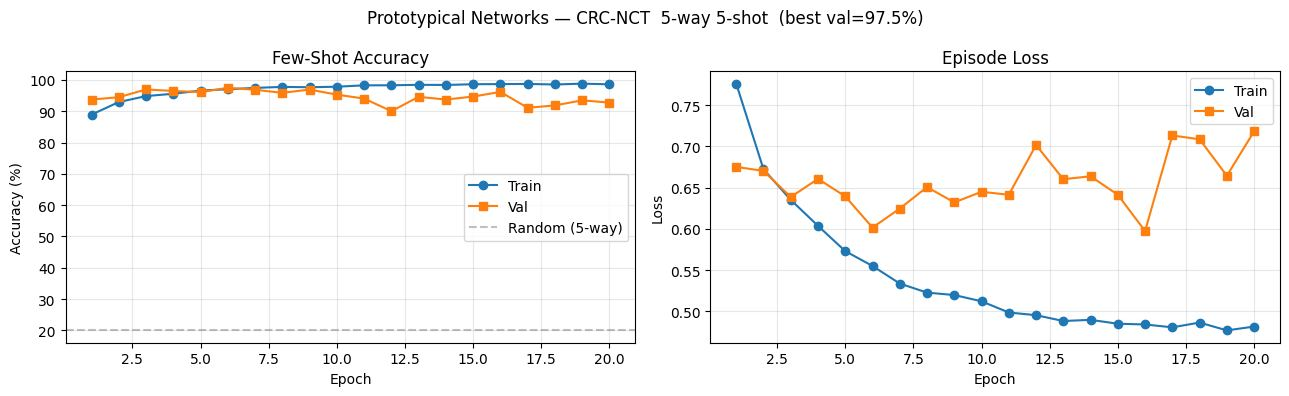

Saved to /kaggle/working


In [12]:
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_acc']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(epochs, history['train_acc'], 'o-', label='Train')
ax1.plot(epochs, history['val_acc'],   's-', label='Val')
ax1.axhline(100/N_WAY, color='gray', linestyle='--',
            alpha=0.5, label=f'Random ({N_WAY}-way)')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy (%)')
ax1.set_title('Few-Shot Accuracy')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, history['train_loss'], 'o-', label='Train')
ax2.plot(epochs, history['val_loss'],   's-', label='Val')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.set_title('Episode Loss')
ax2.legend(); ax2.grid(alpha=0.3)

plt.suptitle(
    f'Prototypical Networks — CRC-NCT  '
    f'{N_WAY}-way {K_SHOT}-shot  '
    f'(best val={best_val_acc:.1f}%)',
    fontsize=12
)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'protonet_curves.png'), dpi=150)
plt.show()
print('Saved to', OUT_DIR)

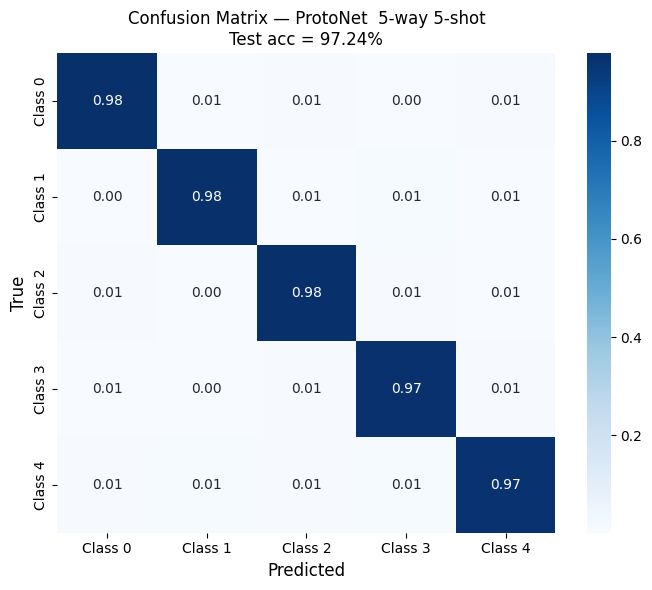


Per-class report:
              precision    recall  f1-score   support

     Class 0       0.98      0.98      0.98      1000
     Class 1       0.98      0.98      0.98      1000
     Class 2       0.97      0.98      0.97      1000
     Class 3       0.97      0.97      0.97      1000
     Class 4       0.97      0.97      0.97      1000

    accuracy                           0.97      5000
   macro avg       0.97      0.97      0.97      5000
weighted avg       0.97      0.97      0.97      5000



In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []

for batch in test_dl:
    for (support, query, s_tgt, q_tgt) in batch:
        support = support.to(DEVICE)
        query   = query.to(DEVICE)
        s_tgt   = s_tgt.to(DEVICE)
        q_tgt   = q_tgt.to(DEVICE)

        with torch.no_grad():
           
            sup_emb    = model(support).view(N_WAY, K_SHOT, -1).mean(dim=1)
           
            qry_emb    = model(query)
           
            dists      = euclidean_dist(qry_emb, sup_emb)
            preds      = torch.argmax(-dists, dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(q_tgt.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)


class_names = [f'Class {i}' for i in range(N_WAY)]

cm      = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names, ax=ax)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('True',      fontsize=12)
ax.set_title(f'Confusion Matrix — ProtoNet  {N_WAY}-way {K_SHOT}-shot\n'
             f'Test acc = {test_acc:.2f}%', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'protonet_confusion_matrix.png'), dpi=150)
plt.show()

print('\nPer-class report:')
print(classification_report(all_labels, all_preds, target_names=class_names))

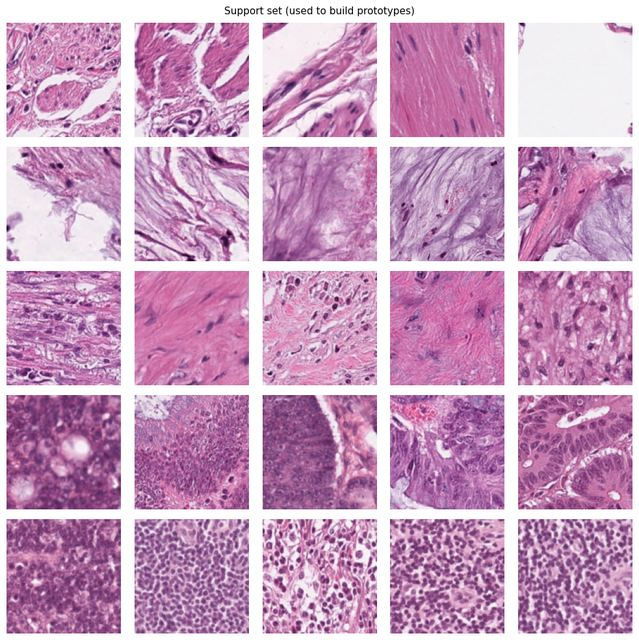

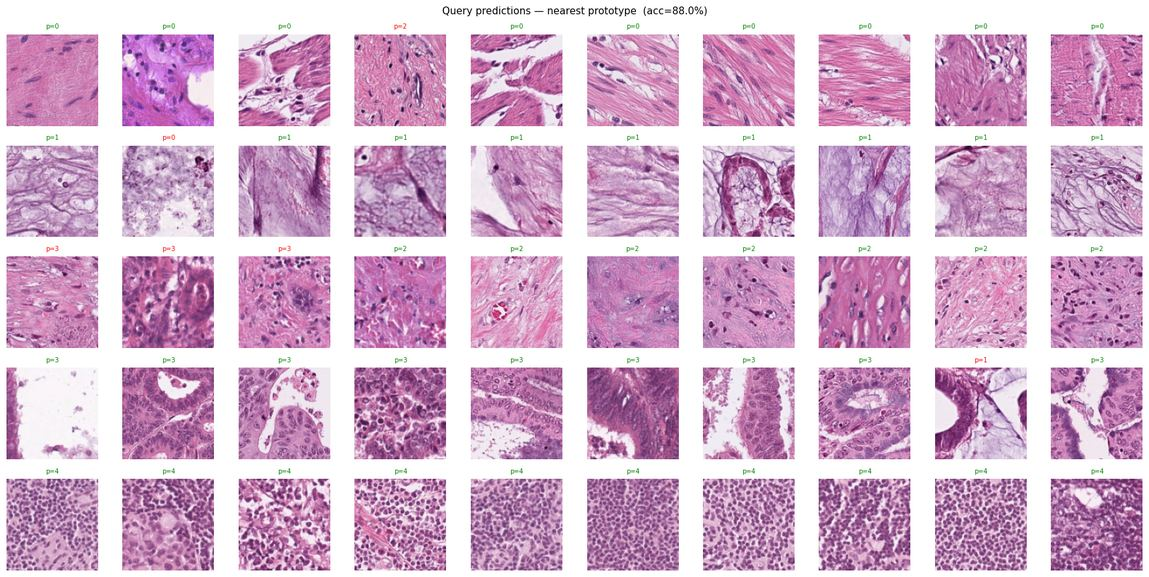

In [13]:
import matplotlib.pyplot as plt

MEAN_T = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
STD_T  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
denorm = lambda t: (t * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()

support, query, s_tgt, q_tgt = val_ds[0]
support = support.to(DEVICE)
query   = query.to(DEVICE)
s_tgt   = s_tgt.to(DEVICE)
q_tgt   = q_tgt.to(DEVICE)

with torch.no_grad():
    _, ep_acc = proto_episode(
        model, support, query, s_tgt, q_tgt, N_WAY, K_SHOT
    )
   
    sup_emb    = model(support).view(N_WAY, K_SHOT, -1).mean(dim=1)
    qry_emb    = model(query)
    dists      = euclidean_dist(qry_emb, sup_emb)
    preds      = torch.argmax(-dists, dim=1).cpu()

support = support.cpu()
query   = query.cpu()


fig, axes = plt.subplots(N_WAY, K_SHOT, figsize=(K_SHOT*2, N_WAY*2))
for i in range(N_WAY):
    for j in range(K_SHOT):
        axes[i,j].imshow(denorm(support[i*K_SHOT+j]))
        axes[i,j].axis('off')
        if j == 0:
            axes[i,j].set_ylabel(f'cls {i}', fontsize=8)
plt.suptitle('Support set (used to build prototypes)', fontsize=11)
plt.tight_layout(); plt.show()

# Query predictions
fig, axes = plt.subplots(N_WAY, Q_QUERY, figsize=(Q_QUERY*1.8, N_WAY*1.8))
for i in range(N_WAY):
    for j in range(Q_QUERY):
        idx  = i*Q_QUERY + j
        pred = preds[idx].item()
        true = q_tgt.cpu()[idx].item()
        axes[i,j].imshow(denorm(query[idx]))
        axes[i,j].set_title(
            f'p={pred}', fontsize=7,
            color='green' if pred == true else 'red'
        )
        axes[i,j].axis('off')
plt.suptitle(
    f'Query predictions — nearest prototype  (acc={ep_acc:.1f}%)',
    fontsize=11
)
plt.tight_layout(); plt.show()